In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

In [2]:
booking_data=pd.read_csv("ride_booking_data.csv")
booking_data

,Booking_ID,Booking_Date,Booking_Time,Customer_ID,Ride_Status,Vehicle_Type,Pickup_Location,Drop_Location,Ride_Distance_KM,Fare_Amount,Payment_Method,Customer_Rating
0,1,02-01-2026,08:15:00,C001,Completed,Mini,Kothrud,Hinjewadi,12.5,185,UPI,4.5
1,2,03-01-2026,09:30:00,C002,Completed,Sedan,Baner,Wakad,8.2,174.4,Cash,4.2
2,3,04-01-2026,10:45:00,C003,Cancelled,Auto,Hadapsar,Kharadi,6.5,0,Cash,NaN
3,4,05-01-2026,11:20:00,C004,Completed,SUV,Viman Nagar,Pune Station,15.8,398.4,UPI,4.8
4,5,06-01-2026,12:10:00,C005,Completed,Mini,Shivajinagar,Kothrud,5.4,102.8,Wallet,4.1
...,...,...,...,...,...,...,...,...,...,...,...,...
495,496,22-02-2026,15:10:00,C129,No Driver,Auto,Hadapsar,Kothrud,7.5,0,UPI,NaN
496,497,25-02-2026,16:25:00,C150,Completed,Sedan,Pune Station,Kharadi,10.8,231.6,Credit Card,4.5
497,1,02-01-2026,08:15:00,C001,Completed,Mini,Kothrud,Hinjewadi,12.5,185,UPI,4.5
498,2,03-01-2026,09:30:00,C002,Completed,Sedan,Baner,Wakad,8.2,174.4,Cash,4.2


In [3]:
booking_data['Booking_Date'] = pd.to_datetime(booking_data['Booking_Date'], 
format="%d-%m-%Y")

booking_data['Booking_Time'] = pd.to_datetime(booking_data['Booking_Time'],
 errors="coerce").dt.hour

booking_data['Fare_Amount'] = pd.to_numeric(
    booking_data['Fare_Amount'].astype(str).str.replace(r"[^\d.]", "", regex=True),
    errors="coerce"
)

booking_data.dtypes

C:\Users\Admin\AppData\Local\Temp\ipykernel_5608\4234624771.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  booking_data['Booking_Time'] = pd.to_datetime(booking_data['Booking_Time'],


Booking_ID                   int64
Booking_Date        datetime64[ns]
Booking_Time                 int32
Customer_ID                 object
Ride_Status                 object
Vehicle_Type                object
Pickup_Location             object
Drop_Location               object
Ride_Distance_KM           float64
Fare_Amount                float64
Payment_Method              object
Customer_Rating            float64
dtype: object

In [4]:
print(booking_data.duplicated().sum())
booking_data=booking_data.drop_duplicates()
print(booking_data.duplicated().sum())

3
0


In [5]:
booking_data = booking_data[booking_data['Ride_Status'] != "Unknown"]
print(booking_data['Ride_Status'].value_counts())

print(booking_data[booking_data["Vehicle_Type"] == "Kharadi"])
booking_data = booking_data[booking_data["Vehicle_Type"] != "Kharadi"]


Ride_Status
Completed    419
Cancelled     42
No Driver     35
Name: count, dtype: int64
Empty DataFrame
Columns: [Booking_ID, Booking_Date, Booking_Time, Customer_ID, Ride_Status, Vehicle_Type, Pickup_Location, Drop_Location, Ride_Distance_KM, Fare_Amount, Payment_Method, Customer_Rating]
Index: []


### Chart 1: Ride Status Distribution

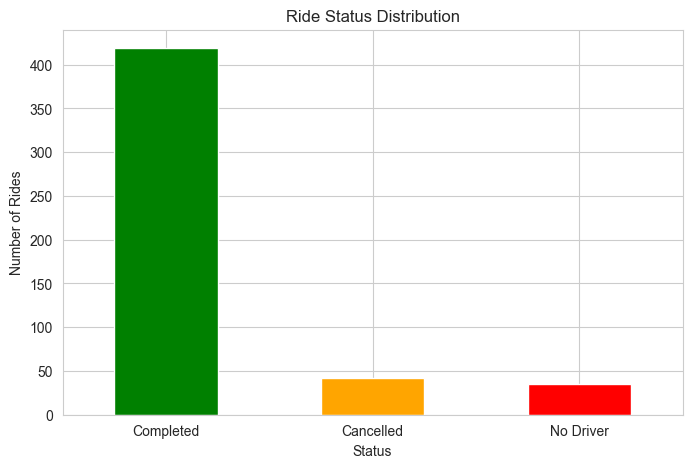

In [6]:
counts = booking_data["Ride_Status"].value_counts()
counts.plot(kind="bar", color=["green", "orange", "red"])
plt.title("Ride Status Distribution")
plt.xlabel("Status")
plt.ylabel("Number of Rides")
plt.xticks(rotation=0)
plt.show()

**Insight:** 419 rides completed,42 cancellled and 35 rides no driver .

### Chart 2: Bookings by Vehicle Type

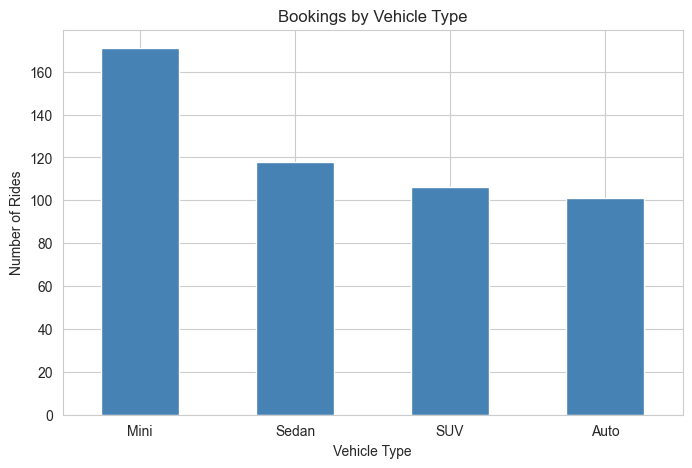

In [7]:
ride_count=booking_data["Vehicle_Type"].value_counts()
ride_count.plot(kind="bar", color="steelblue")
plt.title("Bookings by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Number of Rides")
plt.xticks(rotation=0)
plt.show()

**Insight:** Mini is the most booked vehicle type with 172 rides, followed by Sedan (119), SUV (106) and Auto (102).

### Chart 3: Bookings by Hour of Day

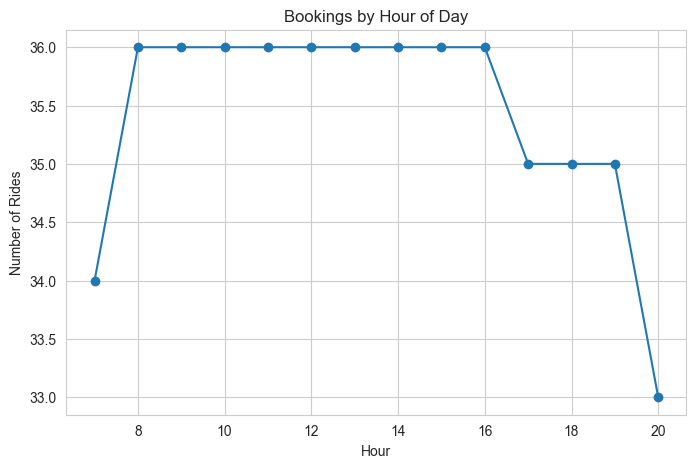

In [8]:

hour_count=booking_data["Booking_Time"].value_counts().sort_index()
hour_count.plot(kind="line", marker="o")
plt.title("Bookings by Hour of Day")
plt.xlabel("Hour")
plt.ylabel("Number of Rides")
plt.show()

**Insight:** Bookings are evenly distributed from 7 AM to 8 PM (33 to 36 rides per hour), with no clear peak hour.

### Chart 4: Fare Amount Distribution

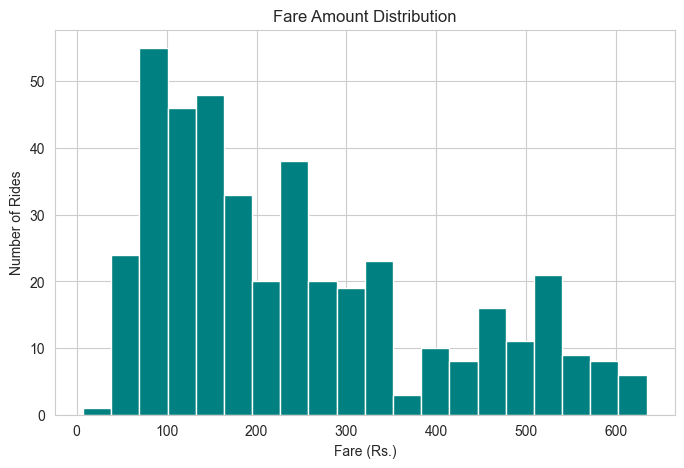

In [9]:

completed = booking_data[booking_data["Ride_Status"] == "Completed"]

plt.hist(completed['Fare_Amount'], bins=20, color="teal", edgecolor="white")
plt.title("Fare Amount Distribution")
plt.xlabel("Fare (Rs.)")
plt.ylabel("Number of Rides")
plt.show()

**Insight:** Most fares fall between Rs. [100] and Rs. [350]. 

### Chart 5: Ride Distance vs Fare

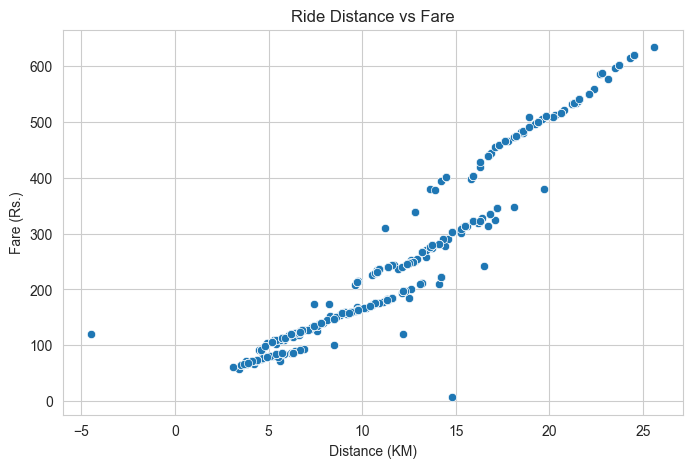

0.9594790683974294


In [10]:
completed = booking_data[booking_data["Ride_Status"] == "Completed"]
sns.scatterplot(data=completed, x="Ride_Distance_KM", y="Fare_Amount")
plt.title("Ride Distance vs Fare")
plt.xlabel("Distance (KM)")
plt.ylabel("Fare (Rs.)")
plt.show()
print(completed["Ride_Distance_KM"].corr(completed["Fare_Amount"]))

**Insight:** For completed rides, fare increases with distance, showing a strong positive relationship (correlation 0.95). Cancelled and no-driver rides were excluded because their fare is zero.

### Chart 6: Payment method

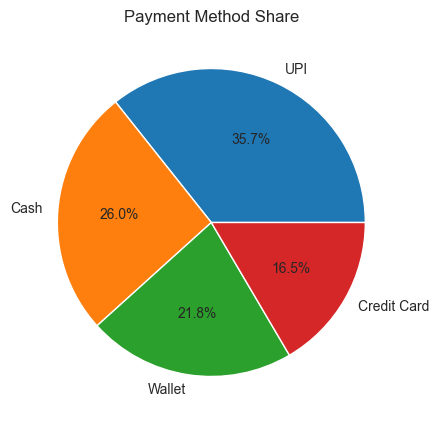

In [11]:
payment_count=booking_data["Payment_Method"].value_counts()
payment_count.plot(kind="pie", autopct="%1.1f%%")
plt.title("Payment Method Share")
plt.ylabel("")
plt.show()

**Insight:** UPI is the most used payment method at 35.7% of bookings, followed by Cash (26.0%), Wallet (21.8%) and Credit Card (16.5%). Digital payments (UPI, Wallet and Credit Card) together make up about 74% of bookings.

**Note:** Payment method is recorded at the time of booking, so cancelled and no-driver bookings also have a payment method.